# S1 · HF365 reprocessed from HLS v2.0

`hf365_v2_candidate` — a proposed successor to the archived HF365, not an archive release.

Source: six AppEEARS point-sample bundles, 95 HLS pixel centres covering the 40 grid plots, 2015→2026, HLSL30.020 + HLSS30.020, tile T18TYN.

Rebuild: `python -m s1 stage 0` → `s1.pipeline.run()` → `s1.results.run()`. This notebook only reads `s1/out/`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import json, numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from s1 import io as sio

BLUE, ORANGE, AQUA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
INK, INK2, MUTED, SURF = '#0b0b0b', '#52514e', '#c9c8c3', '#fcfcfb'
mpl.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF,
                     'text.color': INK, 'axes.labelcolor': INK2,
                     'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.edgecolor': MUTED, 'font.size': 10})
def bare(ax):
    for s in ('top','right'): ax.spines[s].set_visible(False)

OUT = sio.OUT
R    = json.loads((OUT/'results_summary.json').read_text())
v2   = pd.read_csv(OUT/'hf365_v2_candidate.csv')
att  = pd.read_csv(OUT/'result_v14_vs_v20.csv')
conv = pd.read_csv(OUT/'result_convention_vs_fieldlai.csv')
band = pd.read_csv(OUT/'result_convention_by_overlap.csv')
sza  = pd.read_csv(OUT/'result_sza_check.csv')
dens = pd.read_csv(OUT/'observation_density.csv')
print(f"{len(v2):,} plot-acquisitions | {v2.date.nunique():,} dates | {v2['plot'].nunique()} plots")

43,680 plot-acquisitions | 1,012 dates | 40 plots


## What the reprocessing delivers

v1.4 covered 2015-01-23 → 2020-08-10 with three indices and undocumented NAs. v2.0 covers 2015-01-07 → 2026-08-04 with all requested bands, four angle bands, explicit Fmask provenance, and both pixel-assignment conventions.

In [2]:
c = R['coverage']
print(f"v1.4 dates                 {c['dates_v14']:>5}")
print(f"v2.0 dates                 {c['dates_v20']:>5}")
print(f"shared                     {c['dates_in_both']:>5}")
print(f"v2.0 only                  {c['dates_v20_only']:>5}")
print(f"v1.4 only                  {c['dates_v14_only']:>5}   <- dates v1.4 kept that v2.0 masks out")
print()
print('observations per year, by platform:')
piv = dens.pivot_table(index='year', columns='platform', values='n_granules', aggfunc='sum').fillna(0).astype(int)
print(piv.assign(total=piv.sum(axis=1)).to_string())

v1.4 dates                   261
v2.0 dates                  1012
shared                       215
v2.0 only                    797
v1.4 only                     46   <- dates v1.4 kept that v2.0 masks out

observations per year, by platform:
platform  L8  L9  S2A  S2B  S2C  total
year                                  
2015      36   0    1    0    0     37
2016      40   0   13    0    0     53
2017      38   0    9    6    0     53
2018      37   0   24   25    0     86
2019      37   0   24   21    0     82
2020      39   0   25   24    0     88
2021      37   3   24   28    0     92
2022      38  39   22   31    0    130
2023      33  37   22   27    0    119
2024      37  38   29   29    0    133
2025      39  40   12   26   23    140
2026      26  20    7   16   16     85


### Figure 1 · Observation density is not stationary

37 acquisitions in 2015, 140 in 2025. Landsat 9 arrives in 2022; Sentinel-2 only reaches systematic coverage of this tile around 2018.

Any metric sensitive to sampling — gap statistics, composite quality, anything with a trend — is confounded with this. It also breaks S5's stated "~52 weekly dimensions per year" premise.

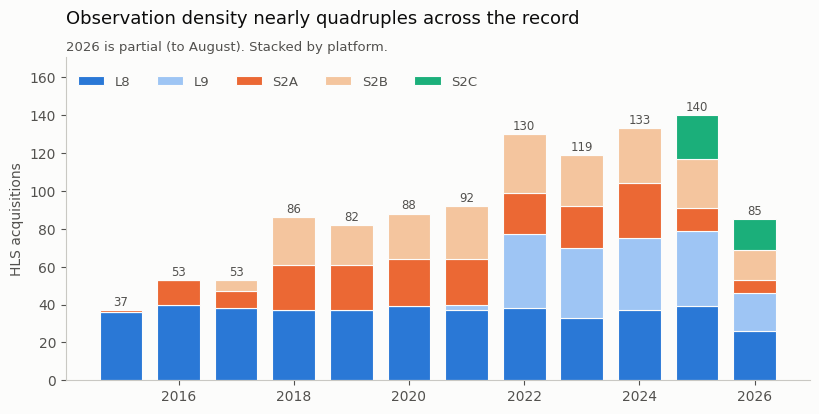

In [3]:
order = ['L8','L9','S2A','S2B','S2C']
cols  = {'L8':BLUE,'L9':'#9ec5f4','S2A':ORANGE,'S2B':'#f4c59e','S2C':AQUA}
p = dens.pivot_table(index='year', columns='platform', values='n_granules', aggfunc='sum').fillna(0)
p = p[[c for c in order if c in p.columns]]

fig, ax = plt.subplots(figsize=(9.6,4.2))
bottom = np.zeros(len(p))
for c in p.columns:
    ax.bar(p.index, p[c], bottom=bottom, color=cols[c], label=c, width=0.74, edgecolor=SURF, lw=0.8)
    bottom += p[c].to_numpy()
for x, tot in zip(p.index, bottom):
    ax.annotate(f'{int(tot)}', (x, tot+2.5), ha='center', fontsize=8.5, color=INK2)
ax.set_ylabel('HLS acquisitions'); ax.set_xlabel('')
ax.set_title('Observation density nearly quadruples across the record', loc='left', fontsize=13, color=INK, pad=24)
ax.annotate('2026 is partial (to August). Stacked by platform.', xy=(0,1.02), xycoords='axes fraction', fontsize=9.5, color=INK2)
ax.legend(frameon=False, ncol=5, fontsize=9.5, labelcolor=INK2, loc='upper left', bbox_to_anchor=(0,0.98))
ax.set_ylim(0, bottom.max()*1.22); bare(ax); plt.show()

## Result 1 · What changed between v1.4 and v2.0

v1.4 is unobtainable from any NASA channel, so the comparison runs against WP0's **recovered** reflectance — inverted in closed form from the three archived indices. That makes this reconstruction-versus-measurement, and the reconstruction has a noise floor which is drawn on the figure.

Restricted to the 215 dates both versions retain.

In [4]:
v = R['v14_vs_v20']
print(f"n = {v['n_observations']:,} observations over {v['n_dates']} shared dates\n")
print(f"  median change in NIR   {v['median_d_nir']:+.5f}   ({100*v['rel_nir_median']:+.1f} % relative)")
print(f"  median change in RED   {v['median_d_red']:+.5f}   ({100*v['rel_red_median']:+.1f} % relative)")
print(f"  |change| NIR / RED     {v['median_abs_d_nir']:.5f} / {v['median_abs_d_red']:.5f}"
      f"  -> NIR moved {v['median_abs_d_nir']/v['median_abs_d_red']:.1f}x more\n")
print(f"  reconstruction floor   NIR {v['reconstruction_floor_nir']:.5f} | RED {v['reconstruction_floor_red']:.6f}")
print(f"  dominant channel       {v['dominant_channel']}\n")
print(f"  growing season d_NIR   {v['growing_d_nir']:+.5f}")
print(f"  off season     d_NIR   {v['off_d_nir']:+.5f}   -> {v['growing_d_nir']/v['off_d_nir']:.1f}x larger in season")

n = 5,867 observations over 211 shared dates

  median change in NIR   +0.01646   (+5.9 % relative)
  median change in RED   +0.00078   (+2.9 % relative)
  |change| NIR / RED     0.02032 / 0.00247  -> NIR moved 8.2x more

  reconstruction floor   NIR 0.00038 | RED 0.000083
  dominant channel       {'nir': 5028, 'red': 830, 'below_reconstruction_floor': 9}

  growing season d_NIR   +0.02979
  off season     d_NIR   +0.00566   -> 5.3x larger in season


### Figure 2 · The change is in the NIR band

Each point is one plot-acquisition. Shaded bands are WP0's reconstruction noise floor (±2σ) — a difference inside the band is not resolvable, and 97.6 % of NIR changes fall outside it.

The change is not a constant offset: it scales with vegetation, being ~5× larger in the growing season.

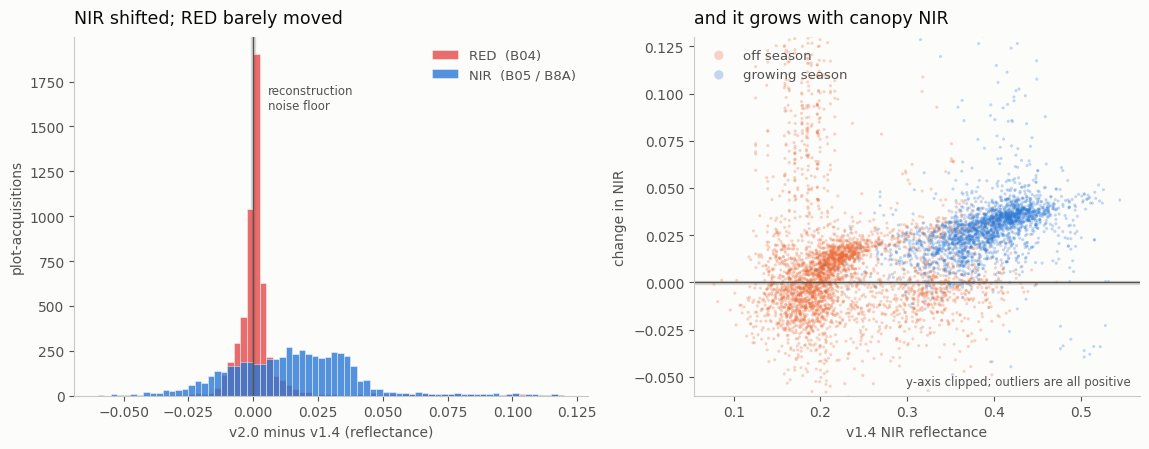

In [5]:
a = att.dropna(subset=['d_nir','d_red'])
fig, axes = plt.subplots(1, 2, figsize=(11.6,4.6), gridspec_kw={'width_ratios':[1.15,1]})

ax = axes[0]
bins = np.arange(-0.06, 0.121, 0.0025)
ax.hist(a.d_red, bins=bins, color=RED,  alpha=.80, label='RED  (B04)', edgecolor=SURF, lw=.4)
ax.hist(a.d_nir, bins=bins, color=BLUE, alpha=.80, label='NIR  (B05 / B8A)', edgecolor=SURF, lw=.4)
ax.axvline(0, color=INK2, lw=1)
fl = v['reconstruction_floor_nir']*2
ax.axvspan(-fl, fl, color=MUTED, alpha=.55, zorder=0)
ax.annotate('reconstruction\nnoise floor', xy=(fl, ax.get_ylim()[1]*.80), xytext=(9,0),
            textcoords='offset points', fontsize=8.5, color=INK2)
ax.set_xlabel('v2.0 minus v1.4 (reflectance)'); ax.set_ylabel('plot-acquisitions')
ax.legend(frameon=False, fontsize=9.5, labelcolor=INK2)
ax.set_title('NIR shifted; RED barely moved', loc='left', fontsize=12.5, color=INK, pad=10); bare(ax)

ax = axes[1]
for s, c, lab in [('off', ORANGE, 'off season'), ('growing', BLUE, 'growing season')]:
    d = a[a.season==s]
    ax.scatter(d.nir_v14, d.d_nir, s=5, alpha=.28, color=c, label=lab, edgecolors='none')
ax.axhline(0, color=INK2, lw=1)
ax.axhspan(-fl, fl, color=MUTED, alpha=.55, zorder=0)
ax.set_ylim(-0.06, 0.13)   # clip: 3.1% of points lie outside, all positive
ax.set_xlabel('v1.4 NIR reflectance'); ax.set_ylabel('change in NIR')
ax.legend(frameon=False, fontsize=9.5, labelcolor=INK2, markerscale=3, loc='upper left')
ax.annotate('y-axis clipped; outliers are all positive', xy=(0.98,0.03),
            xycoords='axes fraction', ha='right', fontsize=8.5, color=INK2)
ax.set_title('and it grows with canopy NIR', loc='left', fontsize=12.5, color=INK, pad=10); bare(ax)
plt.tight_layout(); plt.show()

## Result 2 · Which pixel-assignment convention tracks the ground better

The archive assigns each plot the single pixel containing it. WP0's exact circle-rectangle overlaps make an area-weighted alternative possible. Field PAI, interpolated to acquisition dates, decides.

Restricted to the 34 active tower plots — G3/H3/H4 have no ground data after 1999, and A4/A5/B5 are a harvested stand at a different radius.

**Caveat, and it belongs with the answer:** field PAI is biweekly in the shoulder seasons and monthly mid-summer. It constrains the seasonal trajectory, not individual acquisitions.

In [6]:
print(conv[['measure','convention','n','n_plots','pearson_r','r2','spearman_r','median_per_plot_r']].round(4).to_string(index=False))
print()
print('stratified by how split the plot actually is (NDVI):')
print(band.round(4).to_string(index=False))
print()
h = R['homogeneity']
print(f"between-pixel NDVI sd within a plot footprint : {h['between_pixel_ndvi_sd_median']:.4f}  ({h['as_pct_of_value']:.2f} % of value)")
print(f"seasonal NDVI range within a plot             : {h['seasonal_ndvi_range_median']:.4f}")
print(f"  -> pixel choice contributes {h['noise_as_pct_of_signal']:.1f} % of the seasonal signal")

measure convention    n  n_plots  pearson_r     r2  spearman_r  median_per_plot_r
   ndvi     single 4547       34     0.8688 0.7548      0.8571             0.9307
   ndvi   weighted 4567       34     0.8686 0.7545      0.8560             0.9298
   evi2     single 4547       34     0.8048 0.6476      0.8094             0.9148
   evi2   weighted 4567       34     0.8030 0.6448      0.8078             0.9163
   nirv     single 4547       34     0.7881 0.6211      0.8064             0.9055
   nirv   weighted 4567       34     0.7863 0.6182      0.8047             0.9050

stratified by how split the plot actually is (NDVI):
overlap_band    n  n_plots  r_single  r_weighted  r_weighted_minus_single  median_abs_diff
        <50%  275        2    0.8028      0.7951                  -0.0077           0.0059
      50-80% 2371       18    0.8901      0.8917                   0.0016           0.0027
     80-100%  957        7    0.8314      0.8325                   0.0012           0.0004
fully in

### Figure 3 · The conventions are indistinguishable, and the reason is measurable

A null result. Area-weighting neither helps nor hurts, even for the plots split worst across pixel boundaries.

The mechanism is on the right: neighbouring 30 m pixels inside one plot's footprint differ by an NDVI sd of 0.0085, against a seasonal amplitude of 0.41. The canopy is spatially homogeneous at this scale relative to the plot-pixel offset, so which pixel you take contributes ~2 % of the signal.

**The archive's simpler convention can be kept, with evidence rather than by default.**

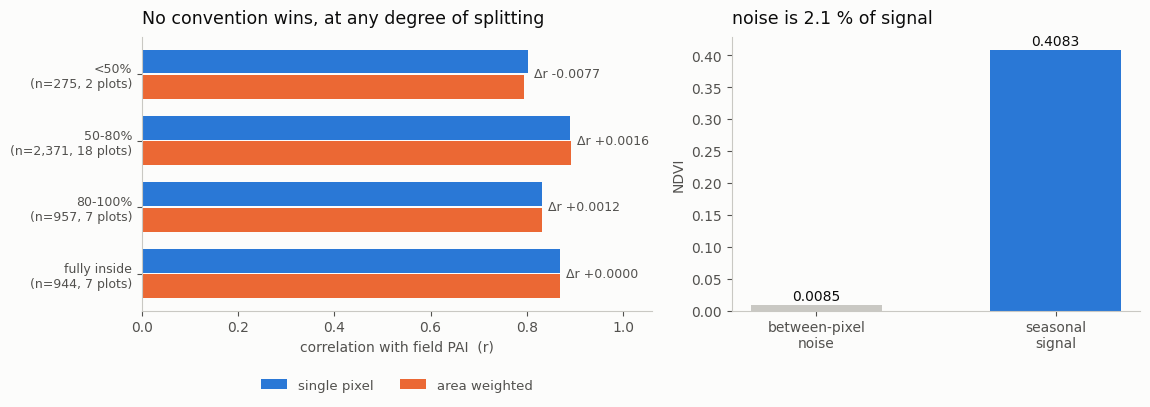

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.6,4.4), gridspec_kw={'width_ratios':[1.25,1]})

ax = axes[0]
y = np.arange(len(band))
ax.barh(y-0.19, band.r_single,   height=.36, color=BLUE,   label='single pixel')
ax.barh(y+0.19, band.r_weighted, height=.36, color=ORANGE, label='area weighted')
for i, r in band.iterrows():
    ax.annotate(f"Δr {r.r_weighted_minus_single:+.4f}", (max(r.r_single,r.r_weighted)+.012, i),
                va='center', fontsize=9, color=INK2)
ax.set_yticks(y); ax.set_yticklabels([f"{b}\n(n={n:,}, {p} plots)" for b,n,p in zip(band.overlap_band,band.n,band.n_plots)], fontsize=9)
ax.set_xlim(0, 1.06); ax.set_xlabel('correlation with field PAI  (r)')
ax.invert_yaxis()
ax.legend(frameon=False, fontsize=9.5, labelcolor=INK2, ncol=2,
          loc='lower center', bbox_to_anchor=(0.5,-0.34))
ax.set_title('No convention wins, at any degree of splitting', loc='left', fontsize=12.5, color=INK, pad=10); bare(ax)

ax = axes[1]
vals = [h['between_pixel_ndvi_sd_median'], h['seasonal_ndvi_range_median']]
ax.bar(['between-pixel\nnoise', 'seasonal\nsignal'], vals, color=[MUTED, BLUE], width=.55)
for i, vv in enumerate(vals):
    ax.annotate(f'{vv:.4f}', (i, vv+.008), ha='center', fontsize=10, color=INK)
ax.set_ylabel('NDVI')
ax.set_title(f"noise is {h['noise_as_pct_of_signal']:.1f} % of signal", loc='left', fontsize=12.5, color=INK, pad=10)
bare(ax); plt.tight_layout(); plt.show()

## Result 3 · Are the shipped angle bands trustworthy

Checked against WP0's independent pvlib solar geometry (NREL SPA) at each acquisition instant.

The two products should *not* agree equally well, and they don't: Landsat angles are derived for the red band and applied to every band, while Sentinel-2's are interpolated from ESA's 5 km grid using the 2nd red-edge band's view angle. S4's matched-SZA design depends on these bands, so the size of that residual is a number it needs.

In [8]:
print(sza.groupby(['product','angle_provenance'])['sza_residual']
        .agg(n='size', median='median', mad=lambda s:(s-s.median()).abs().median(),
             p05=lambda s: s.quantile(.05), p95=lambda s: s.quantile(.95)).round(4).to_string())
print()
print(f"overall median {R['sza']['median_residual_deg']:+.3f} deg | "
      f"{100*R['sza']['frac_over_1deg']:.1f} % of acquisitions exceed 1 deg")
print()
print('by platform (an offset that is a product property, not sensor drift):')
print(sza.groupby('platform')['sza_residual'].agg(n='size', median='median').round(3).to_string())

                                                   n  median     mad     p05     p95
product angle_provenance                                                            
L30     L30_red_band_applied_to_all              609  0.1733  0.3155 -0.3565  0.4729
S30     S30_rededge2_interpolated_from_5km_grid  483  0.5678  0.1956 -1.6756  0.9079

overall median +0.320 deg | 2.9 % of acquisitions exceed 1 deg

by platform (an offset that is a product property, not sensor drift):
            n  median
platform             
L8        433   0.169
L9        176   0.175
S2A       211   0.555
S2B       233   0.575
S2C        39   0.585


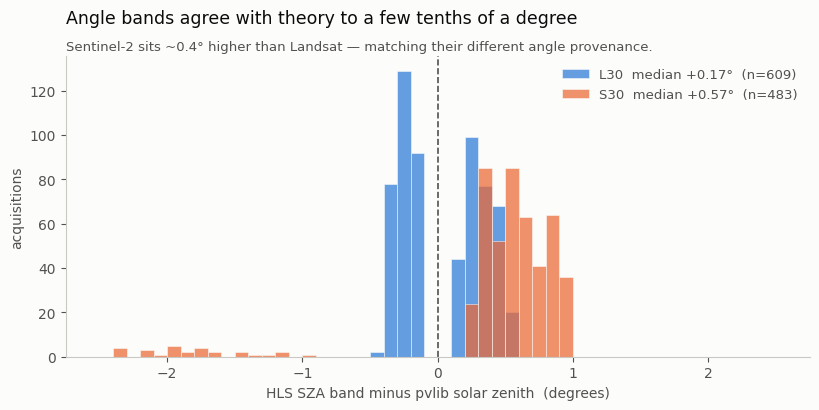

In [9]:
fig, ax = plt.subplots(figsize=(9.6,3.9))
bins = np.arange(-2.5, 2.55, 0.1)
for prod, c in [('L30', BLUE), ('S30', ORANGE)]:
    d = sza[sza['product']==prod]
    ax.hist(d.sza_residual, bins=bins, alpha=.72, color=c, edgecolor=SURF, lw=.5,
            label=f"{prod}  median {d.sza_residual.median():+.2f}°  (n={len(d)})")
ax.axvline(0, color=INK2, lw=1.2, ls='--')
ax.set_xlabel('HLS SZA band minus pvlib solar zenith  (degrees)'); ax.set_ylabel('acquisitions')
ax.legend(frameon=False, fontsize=9.5, labelcolor=INK2)
ax.set_title('Angle bands agree with theory to a few tenths of a degree', loc='left', fontsize=12.5, color=INK, pad=24)
ax.annotate('Sentinel-2 sits ~0.4° higher than Landsat — matching their different angle provenance.',
            xy=(0,1.02), xycoords='axes fraction', fontsize=9.5, color=INK2)
bare(ax); plt.show()

## Masking provenance

v1.4 shipped undocumented NAs. Every exclusion here is attributable, including the provider's own discard rule for high-aerosol retrievals — HLS known issue #1 states such pixels should be dropped, and in this record 98.8 % of the negative red reflectances carry that flag.

Cirrus is the one gap that cannot be closed from QA: Table 9 bit 0 is *"Reserved, but not used in HLS V2.0"*, confirmed here across all 103,143 real observations. A cirrus proxy from the cirrus band ships instead, labelled as S1-derived.

In [10]:
pix = pd.read_csv(OUT/'hls_v2_pixels.csv',
                  usecols=['usable','rejected_reason','cloud','cloud_shadow',
                           'adjacent_cloud_shadow','snow_ice','water','aerosol_level'])
n = len(pix)
print(f"{n:,} pixel-observations, {pix.usable.sum():,} usable ({100*pix.usable.mean():.1f} %)\n")
print('rejection reason:')
print((pix.loc[~pix.usable,'rejected_reason'].value_counts()
        .rename('n').to_frame().assign(pct=lambda d: (100*d.n/n).round(2)).to_string()))
print('\nflag prevalence (not mutually exclusive — the User Guide is explicit about this):')
for c in ['cloud','adjacent_cloud_shadow','cloud_shadow','snow_ice','water']:
    print(f'  {c:<24} {100*pix[c].mean():5.1f} %')
clean = pix[~pix.cloud & ~pix.cloud_shadow & ~pix.snow_ice & ~pix.adjacent_cloud_shadow & (pix.aerosol_level>=0)]
print(f'\namong cloud-free pixels, aerosol level: '
      f'high {100*(clean.aerosol_level==3).mean():.1f} % | '
      f'moderate {100*(clean.aerosol_level==2).mean():.1f} % | '
      f'low {100*(clean.aerosol_level==1).mean():.1f} %')

103,348 pixel-observations, 32,694 usable (31.6 %)

rejection reason:
                              n    pct
rejected_reason                       
fmask                     68117  65.91
reflectance_out_of_range   2332   2.26
fill                        205   0.20

flag prevalence (not mutually exclusive — the User Guide is explicit about this):
  cloud                     49.1 %
  adjacent_cloud_shadow      5.6 %
  cloud_shadow               5.3 %
  snow_ice                   5.5 %
  water                      0.0 %

among cloud-free pixels, aerosol level: high 12.2 % | moderate 11.2 % | low 76.6 %


## Carried forward

**To S5** — observation density is non-stationary (37→140/yr) and 224 of 484 S30 granules rest on pre-Collection-1 L1C that ESA has since reprocessed and HLS has not rebuilt from. Neither is safe to pool across.

**To S4** — angle bands are good to ~0.2° (L30) and ~0.6° (S30), with the offset a product property rather than sensor drift.

**To S7** — masking is strongly correlated across plots: cloud and shadow are dilated 5 pixels (150 m) while the network spans ~500 m, so 40 plots on a date are nowhere near 40 independent samples.

**Not done** — `HARV_049` and `HARV_050` are NEON plots whose coordinates are not in the Harvard Forest archive, so this reproduces 40 of HF365's 42 columns.